# B1938+666: draw an exclusion mask on the recentered S/N map

Read the recentered science and one-sigma noise images, compute **S/N = science / sigma**, and pass the S/N **array** to `FitsMaskEditor`.

Run the cells in order in the `tinylens_gpu` environment with `ipympl` installed. The default filter is **F115W**; change `BAND` to **F277W** to edit the other filter. Their grids have different shapes, so each filter has its own output mask.

- Hover over the image to inspect the pixel's S/N value.
- Hold **Ctrl** and move to paint; hold **Shift** and move to erase.
- Adjust **Diameter (px)** to change the brush size.
- Click **Save mask (overwrite)** to save the current mask to `OUTPUT_PATH`.
- **1 / True = marked and excluded from fitting; 0 / False = unmarked.**
- Click the image for keyboard focus. If modifier keys are intercepted, select **Paint** or **Erase** and drag with the left mouse button.

The sigma map stores the pipeline's one-sigma uncertainty, so no square root is needed. The ratio uses the delivered recentered science values without further background subtraction. Display clipping only changes colors, not S/N values or saved mask pixels.


In [1]:
%matplotlib widget


In [2]:
from pathlib import Path
import importlib
import sys

import matplotlib.pyplot as plt
import numpy as np
from astropy.io import fits
from IPython.display import display

# Locate the repository from this notebook directory or the repository root.
for candidate in (Path.cwd(), *Path.cwd().parents):
    if (candidate / "examples" / "mask_tool" / "mask_tool.py").is_file():
        REPO_ROOT = candidate
        break
else:
    raise FileNotFoundError("Run this notebook from within the TinyLensGpu repository.")

TOOL_DIR = REPO_ROOT / "examples" / "mask_tool"
if str(TOOL_DIR) not in sys.path:
    sys.path.insert(0, str(TOOL_DIR))
import mask_tool
mask_tool = importlib.reload(mask_tool)
FitsMaskEditor = mask_tool.FitsMaskEditor


In [3]:
# Choose F115W or F277W, then rerun the following cells.
# BAND = "F115W"
BAND = "F115W"
BRUSH_SIZE = 5
RESUME_MASK = True  # Resume an existing output mask when available.

DATA_DIR = REPO_ROOT / "examples" / "pix_src_demo_operator" / "pipe" / "subhalo_B1938" / "data"
if BAND not in {"F115W", "F277W"}:
    raise ValueError("BAND must be F115W or F277W.")

SCIENCE_PATH = DATA_DIR / f"B1938_666_{BAND}_recentered_science.fits"
NOISE_PATH = DATA_DIR / f"B1938_666_{BAND}_recentered_sigma.fits"
OUTPUT_PATH = DATA_DIR / f"B1938_666_{BAND}_mask.fits"

# Display limits affect colors only. Set SNR_VMAX to a number if desired.
SNR_VMIN = 0.0
SNR_VMAX = None  # Use the 99th percentile of valid S/N values.

print(f"Science: {SCIENCE_PATH}")
print(f"Noise (1-sigma): {NOISE_PATH}")
print(f"Mask output: {OUTPUT_PATH}")


Science: /home/xycao/workspace/tinylens_dev/TinyLensGpu/examples/pix_src_demo_operator/pipe/subhalo_B1938/data/B1938_666_F115W_recentered_science.fits
Noise (1-sigma): /home/xycao/workspace/tinylens_dev/TinyLensGpu/examples/pix_src_demo_operator/pipe/subhalo_B1938/data/B1938_666_F115W_recentered_sigma.fits
Mask output: /home/xycao/workspace/tinylens_dev/TinyLensGpu/examples/pix_src_demo_operator/pipe/subhalo_B1938/data/B1938_666_F115W_mask.fits


In [4]:
# Read the FITS images outside the editor; both products use the primary HDU.
science, science_header = fits.getdata(SCIENCE_PATH, ext=0, header=True)
noise, noise_header = fits.getdata(NOISE_PATH, ext=0, header=True)
science = np.asarray(science, dtype=np.float64)
noise = np.asarray(noise, dtype=np.float64)

if science.ndim != 2 or science.shape != noise.shape:
    raise ValueError("Science and noise must be 2-D arrays with the same shape.")
if science_header.get("BUNIT") != noise_header.get("BUNIT"):
    raise ValueError("Science and sigma must use the same units.")

valid = np.isfinite(science) & np.isfinite(noise) & (noise > 0)
snr = np.full(science.shape, np.nan, dtype=np.float64)
np.divide(science, noise, out=snr, where=valid)
valid &= np.isfinite(snr)
if not valid.any():
    raise ValueError("No valid science / sigma pixels are available.")

# Exclude invalid data and optionally resume a previously saved binary mask.
initial_mask = ~valid
if RESUME_MASK and OUTPUT_PATH.exists():
    saved_mask = fits.getdata(OUTPUT_PATH, ext=0)
    if saved_mask.shape != science.shape or not np.all((saved_mask == 0) | (saved_mask == 1)):
        raise ValueError("The saved mask must match the image shape and contain only 0/1.")
    initial_mask |= saved_mask.astype(bool)
    print(f"Resuming mask: {OUTPUT_PATH}")

mask_header = science_header.copy()
mask_header["IMAGETYP"] = "Binary exclusion mask"
mask_header["MASKBAND"] = BAND
mask_header.add_history("Mask edited on recentered S/N = science / one-sigma noise.")

print(f"Array shape: {science.shape}")
print(f"Science and sigma unit: {science_header.get('BUNIT')}")
print(f"Valid pixels: {int(valid.sum())} / {valid.size}")
print("S/N percentiles [1, 50, 95, 99]:", np.percentile(snr[valid], [1, 50, 95, 99]))


Resuming mask: /home/xycao/workspace/tinylens_dev/TinyLensGpu/examples/pix_src_demo_operator/pipe/subhalo_B1938/data/B1938_666_F115W_mask.fits
Array shape: (334, 334)
Science and sigma unit: MJy/sr
Valid pixels: 111556 / 111556
S/N percentiles [1, 50, 95, 99]: [-1.08924338  1.61506947 22.60302196 99.78036325]


## Interactive mask editor

The image and hover values below are **S/N**, rather than science intensity. Saving writes a binary exclusion mask with the science image's shape, array orientation, and WCS.

Save before rerunning this cell or switching filters; creating an editor discards unsaved strokes. To resume the latest file, rerun the data-loading cell first. Closing the figure does not save automatically.


Tool code: /home/xycao/workspace/tinylens_dev/TinyLensGpu/examples/mask_tool/mask_tool.py


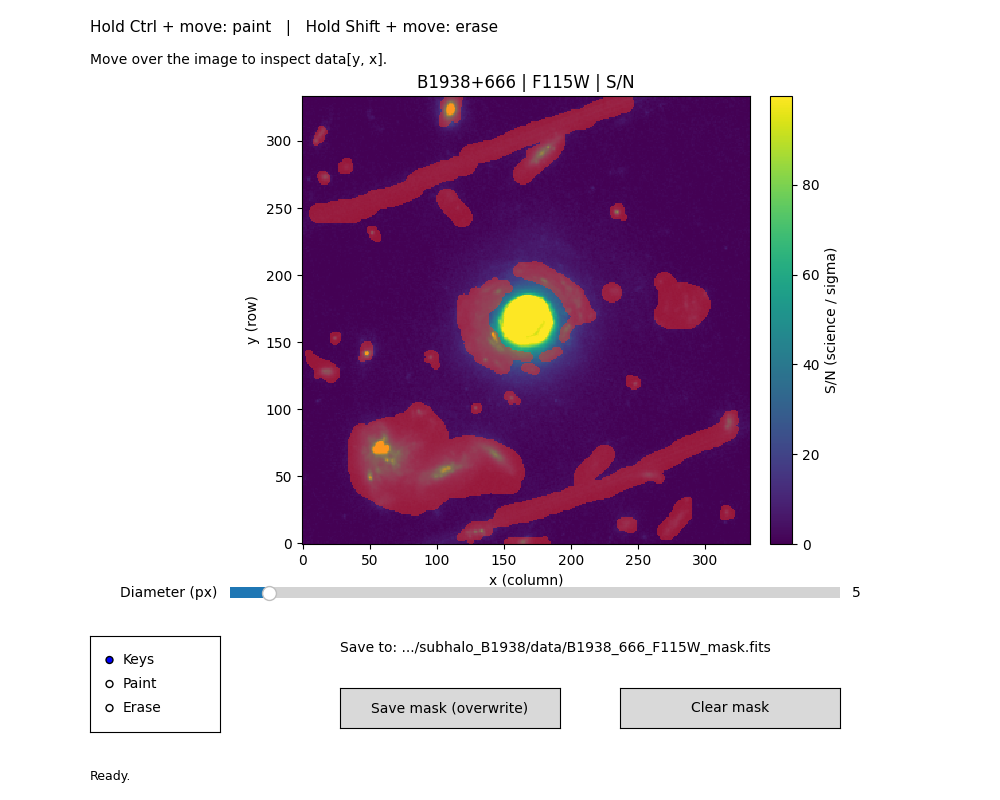

In [5]:
# Close the previous figure and reload the editor to avoid stale imports.
if "editor" in globals():
    plt.close(editor.fig)
mask_tool = importlib.reload(importlib.import_module("mask_tool"))
FitsMaskEditor = mask_tool.FitsMaskEditor
print(f"Tool code: {Path(mask_tool.__file__).resolve()}")

vmax = float(np.percentile(snr[valid], 99)) if SNR_VMAX is None else float(SNR_VMAX)
if vmax <= SNR_VMIN:
    raise ValueError("SNR_VMAX must be greater than SNR_VMIN.")

with plt.ioff():
    editor = FitsMaskEditor(
        snr,
        output_path=OUTPUT_PATH,
        header=mask_header,
        title=f"B1938+666 | {BAND} | S/N",
        initial_mask=initial_mask,
        brush_size=BRUSH_SIZE,
        cmap="viridis",
        vmin=SNR_VMIN,
        vmax=vmax,
    )
    editor.colorbar.set_label("S/N (science / sigma)")
display(editor.fig.canvas)


## Save or inspect the current mask from Python

Use the figure's Save button, or uncomment the save lines below. FITS output contains `uint8` values **0 and 1**; read it with `.astype(bool)` for fitting. Nothing is saved automatically by running this notebook.


In [15]:
print("Mask shape:", editor.mask.shape)
print("Mask dtype:", editor.mask.dtype)
print("Excluded pixels:", int(editor.mask.sum()))
print("Output:", editor.output_path)

# Uncomment to save and verify the latest mask.
# saved_path = editor.save()
# loaded_mask = fits.getdata(saved_path, ext=0).astype(bool)
# np.testing.assert_array_equal(loaded_mask, editor.mask)


Mask shape: (334, 334)
Mask dtype: bool
Excluded pixels: 24049
Output: /home/xycao/workspace/tinylens_dev/TinyLensGpu/examples/pix_src_demo_operator/pipe/subhalo_B1938/data/B1938_666_F115W_mask.fits
